<a href="https://colab.research.google.com/github/JulienRequa/exoplanet-search/blob/main/exoplanet_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install lightkurve: a toolbox for downloading and analyzing NASA TESS/Kepler data
# (The red "dependency resolver" warning is harmless: other Colab packages, not used here)
!pip install lightkurve -q

In [ ]:
import lightkurve as lk   # load the toolbox, nicknamed "lk"

# Ask NASA's archive for every TESS observation of the star WASP-18,
# using the official SPOC pipeline's processed data
search = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC")
search   # show the table: each row = one sector (~27 days of observing)

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,SPOC,120,100100827,0.0
1,TESS Sector 03,2018,SPOC,120,100100827,0.0
2,TESS Sector 29,2020,SPOC,20,100100827,0.0
3,TESS Sector 30,2020,SPOC,20,100100827,0.0
4,TESS Sector 29,2020,SPOC,120,100100827,0.0
5,TESS Sector 30,2020,SPOC,120,100100827,0.0
6,TESS Sector 69,2023,SPOC,20,100100827,0.0
7,TESS Sector 69,2023,SPOC,120,100100827,0.0
8,TESS Sector 96,2025,SPOC,20,100100827,0.0


### Search results
- 18 data products for WASP-18 (TIC 100100827), sectors from 2018–2026
- exptime = how often TESS records brightness (20 s or 120 s)
- Each sector ≈ 27 days of continuous watching

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

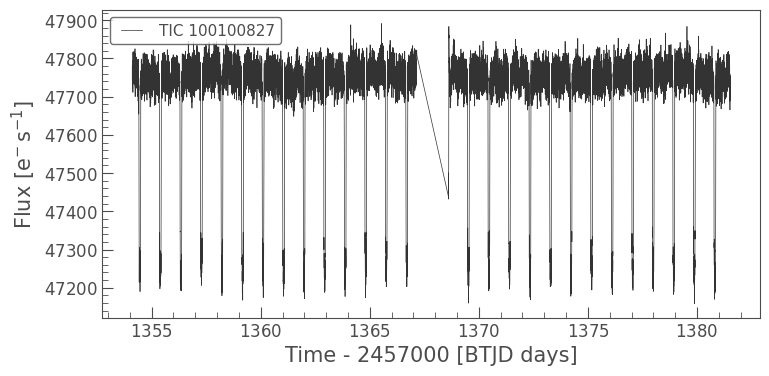

In [ ]:
lc = search[0].download()   # download row 0 = Sector 2 (2018); lc = "light curve"
lc.plot()                   # plot brightness (electrons/sec) vs. time (days)

### Raw light curve (Sector 2)
- Y = light hitting the camera (~47,750 e⁻/s); X = time in days
- Big regular dips = planet passing in front of the star (transits)
- Period by eye: just under 1 day (~0.94 d)
- Gap near day 1368 = TESS pausing to send data to Earth (diagonal line isn't real data)
- Wiggles ±50 (~0.1%) = noise: random photon arrival, camera, star flicker
- Dip (~1%) is ~10× bigger than the noise → easy to see

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

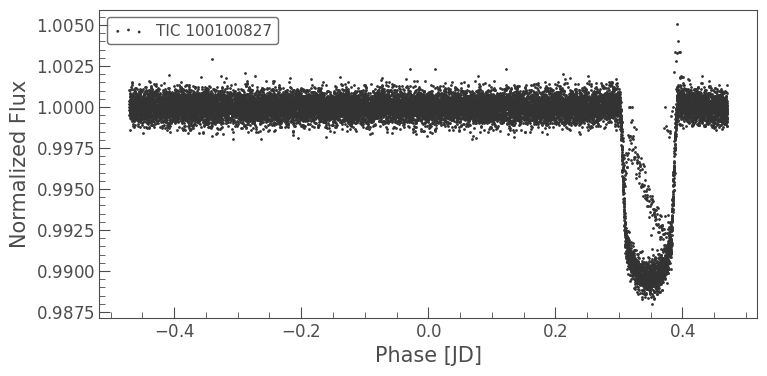

In [ ]:
# flatten(): remove slow drifts and rescale so normal brightness = 1.000
# fold(): cut data into chunks one orbit long (0.9414526 days) and stack them
# scatter(): plot as dots instead of a line
lc.flatten().fold(period=0.9414526).scatter()

### Folded transit
- All ~27 transits stacked → noise averages out, true shape shows
- Depth ≈ 1.000 → 0.9895 ≈ 1.05% of the starlight blocked
  -  $\delta \approx (R_p/R_s)^2$ → planet size
- Duration ≈ phase 0.31 → 0.39 ≈ 0.08 days ≈ 2 hours
- Rounded (U-shaped) bottom = limb darkening (star dimmer at edges) → planet-like
- Dip sits at 0.35, not 0, because no transit time (epoch) was given yet
- Scatter above/below 1.000 = normal noise around the average

### Open questions
- Spike to ~1.005 right after the dip + faint trail inside the dip:
  likely flatten() distorting the transits → fix by masking transits before flattening